<a href="https://colab.research.google.com/github/abhishekmanu268-code/case_study_pp/blob/main/Case_Study_ABHISHEKMS_PRE.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Case Study Assessment — NYC Airbnb Data Preprocessing
### Student Name:Abhishek ms
### Date:06/09/2026

This notebook is your submission template. Fill in each section — do not delete the headers. Use markdown cells for your written justifications, right next to the code that supports them.

In [4]:
import pandas as pd
url = "https://raw.githubusercontent.com/erkansirin78/datasets/master/AB_NYC_2019.csv"
df = pd.read_csv(url)
df.head()

,id,name,host_id,host_name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365
0,2539,Clean & quiet apt home by the park,2787,John,Brooklyn,Kensington,40.64749,-73.97237,Private room,149,1,9,2018-10-19,0.21,6,365
1,2595,Skylit Midtown Castle,2845,Jennifer,Manhattan,Midtown,40.75362,-73.98377,Entire home/apt,225,1,45,2019-05-21,0.38,2,355
2,3647,THE VILLAGE OF HARLEM....NEW YORK !,4632,Elisabeth,Manhattan,Harlem,40.80902,-73.94190,Private room,150,3,0,NaN,NaN,1,365
3,3831,Cozy Entire Floor of Brownstone,4869,LisaRoxanne,Brooklyn,Clinton Hill,40.68514,-73.95976,Entire home/apt,89,1,270,2019-07-05,4.64,1,194
4,5022,Entire Apt: Spacious Studio/Loft by central park,7192,Laura,Manhattan,East Harlem,40.79851,-73.94399,Entire home/apt,80,10,9,2018-11-19,0.10,1,0


---
## Part 1 — Data Understanding & Quality Audit

In [5]:
# TODO: shape, dtypes, missing value summary
#Shape
df.shape

(48895, 16)

In [6]:
df.dtypes  #Data Type

,0
id,int64
name,object
host_id,int64
host_name,object
neighbourhood_group,object
neighbourhood,object
latitude,float64
longitude,float64
room_type,object
price,int64


In [7]:
df.isnull().sum()  #Missing value

,0
id,0
name,16
host_id,0
host_name,21
neighbourhood_group,0
neighbourhood,0
latitude,0
longitude,0
room_type,0
price,0


In [8]:
print("\nColumn Names:")
print(df.columns.tolist())


Column Names:
['id', 'name', 'host_id', 'host_name', 'neighbourhood_group', 'neighbourhood', 'latitude', 'longitude', 'room_type', 'price', 'minimum_nights', 'number_of_reviews', 'last_review', 'reviews_per_month', 'calculated_host_listings_count', 'availability_365']


In [9]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48895 entries, 0 to 48894
Data columns (total 16 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   id                              48895 non-null  int64  
 1   name                            48879 non-null  object 
 2   host_id                         48895 non-null  int64  
 3   host_name                       48874 non-null  object 
 4   neighbourhood_group             48895 non-null  object 
 5   neighbourhood                   48895 non-null  object 
 6   latitude                        48895 non-null  float64
 7   longitude                       48895 non-null  float64
 8   room_type                       48895 non-null  object 
 9   price                           48895 non-null  int64  
 10  minimum_nights                  48895 non-null  int64  
 11  number_of_reviews               48895 non-null  int64  
 12  last_review                     

In [10]:
# TODO: check for values that are technically present but don't make real-world sense
if "price" in df.columns:
    invalid_price = df[df["price"] <= 0][["id", "name", "price"]]
    print("Invalid price values:")
    print(invalid_price)
print("Invalid price/rent values:", len(invalid_price))


Invalid price values:
             id                                               name  price
23161  18750597  Huge Brooklyn Brownstone Living, Close to it all.      0
25433  20333471      ★Hostel Style Room | Ideal Traveling Buddies★      0
25634  20523843    MARTIAL LOFT 3: REDEMPTION (upstairs, 2nd room)      0
25753  20608117                    Sunny, Quiet Room in Greenpoint      0
25778  20624541      Modern apartment in the heart of Williamsburg      0
25794  20639628  Spacious comfortable master bedroom with nice ...      0
25795  20639792  Contemporary bedroom in brownstone with nice view      0
25796  20639914       Cozy yet spacious private brownstone bedroom      0
26259  20933849                              the best you can find      0
26841  21291569  Coliving in Brooklyn! Modern design / Shared room      0
26866  21304320             Best Coliving space ever! Shared room.      0
Invalid price/rent values: 11


**Written notes — what did you find, and what looks suspicious?**

The dataset contain 48,895 rows and 16 columns by checking shape of the dataset

The dataset contain interger,float and object as data type.

The missing-value check found missing data in name, host_name, last_review, and reviews_per_month.
last_review and reviews_per_month contain more missing values.

In [11]:
# TODO: duplicate check
print(df.duplicated().sum())

0


---
## Part 2 — Missing Value Diagnosis & Treatment

In [12]:
# TODO: investigate missingness pattern(s) across columns
df.isnull().sum()

,0
id,0
name,16
host_id,0
host_name,21
neighbourhood_group,0
neighbourhood,0
latitude,0
longitude,0
room_type,0
price,0


In [13]:
print("\nLast review vs number of reviews:")
print(pd.crosstab(df.number_of_reviews == 0, df.last_review.isnull()))

print("\nReviews per month vs number of reviews:")
print(pd.crosstab(df.number_of_reviews == 0, df.reviews_per_month.isnull()))


Last review vs number of reviews:
last_review        False  True 
number_of_reviews              
False              38843      0
True                   0  10052

Reviews per month vs number of reviews:
reviews_per_month  False  True 
number_of_reviews              
False              38843      0
True                   0  10052


**Written justification — MCAR / MAR / MNAR classification per column, and your reasoning:**

name — MCAR:
There are only 16 missing values in the name column, so the amount of missing data is extremely low. No obvious connection was found between these missing values and the other columns. Based on this, the missing values are assumed to be MCAR.

host_name — MCAR:
The host_name column has just 21 missing values. Since very few records are affected and there is no noticeable pattern linked to other variables, these values can be treated as MCAR.

last_review — MAR:
The missing values in last_review are mainly explained by whether a property has received reviews. In fact, the 10,052 properties with zero reviews do not have a last review date. Properties that have received at least one review generally have a date recorded. Because the missingness is connected to the known number_of_reviews value, it is classified as MAR.

reviews_per_month — MAR:
A similar situation is seen with reviews_per_month. The 10,052 properties with no reviews have no monthly review value because there are no reviews to calculate it from. Properties with reviews have this information available. Since the missing values are related to the observed number_of_reviews column, this is also classified as MAR.

In [14]:
# TODO: apply your chosen treatment(s)
df["name"] = df["name"].fillna("Unknown")

# Fill missing host_name values
df["host_name"] = df["host_name"].fillna("Unknown")

# Fill missing last_review values and reviews_per_month values
# "No Review" is appropriate because these listings have no reviews
df["last_review"] = df["last_review"].fillna("No Review")
df["reviews_per_month"] = df["reviews_per_month"].fillna(0)

In [15]:
print(df.isnull().sum())

id                                0
name                              0
host_id                           0
host_name                         0
neighbourhood_group               0
neighbourhood                     0
latitude                          0
longitude                         0
room_type                         0
price                             0
minimum_nights                    0
number_of_reviews                 0
last_review                       0
reviews_per_month                 0
calculated_host_listings_count    0
availability_365                  0
dtype: int64


**Written justification — why this treatment for each column, and what you'd risk with `dropna()` instead:**

name: Missing names were filled with "Unknown" so that the listings are not lost and it is clear that the name was not available.

host_name: Missing host names were also replaced with "Unknown". Since there are only a few missing entries, keeping these rows helps preserve the original dataset.

last_review: Missing values were changed to "No Review" because the analysis showed that the 10,052 listings with zero reviews do not have a review date.

reviews_per_month: Missing values were changed to 0 because properties with no reviews cannot have a monthly review count. Using 0 correctly represents this situation.

Risk of using df.dropna(): Applying df.dropna() to the complete dataset could remove all rows that contain even one missing value. This may lead to unnecessary data loss and reduce the number of useful records available for analysis.

---
## Part 3 — Outlier Detection & Treatment

In [16]:
# TODO: detect outliers in at least two numeric columns
import matplotlib.pyplot as plt
import seaborn as sns

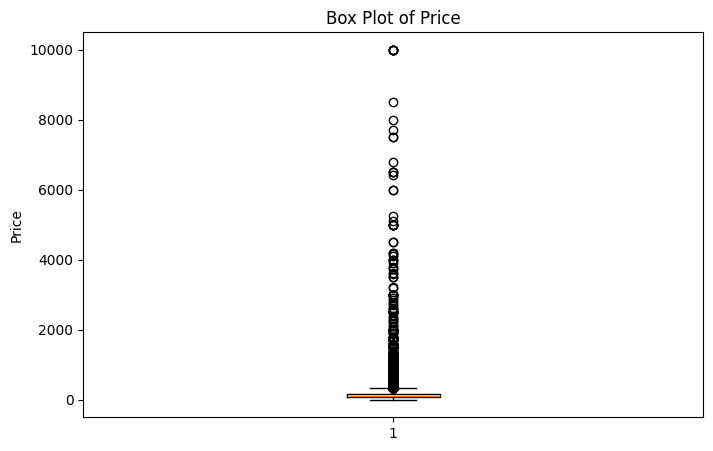

In [17]:
# Box plot for price
plt.figure(figsize=(8, 5))
plt.boxplot(df["price"])
plt.title("Box Plot of Price")
plt.ylabel("Price")
plt.show()

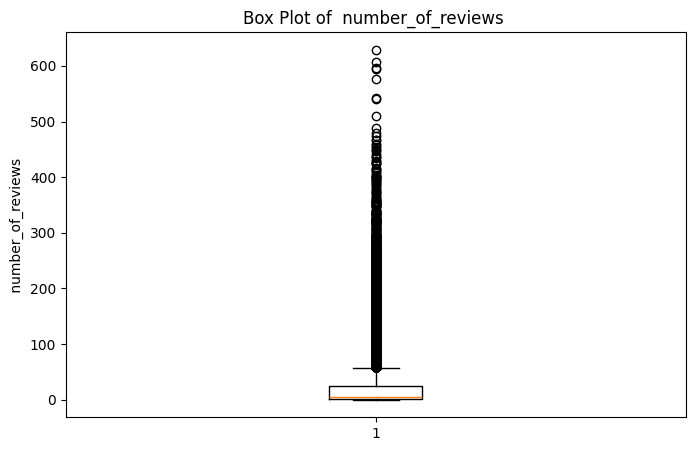

In [18]:
# Box plot for price
plt.figure(figsize=(8, 5))
plt.boxplot(df["number_of_reviews"])
plt.title("Box Plot of  number_of_reviews ")
plt.ylabel(" number_of_reviews ")
plt.show()

In [19]:
Q1 = df.groupby("room_type")["price"].transform("quantile", 0.25)
Q3 = df.groupby("room_type")["price"].transform("quantile", 0.75)

IQR = Q3 - Q1

lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

price_outliers = df[
    (df["price"] < lower_limit) |
    (df["price"] > upper_limit)
]

print("Number of price outliers:", len(price_outliers))

print(price_outliers[
    ["price", "room_type", "neighbourhood"]
].head(20))

Number of price outliers: 3244
     price        room_type     neighbourhood
76     200     Private room   Upper East Side
85     800  Entire home/apt  Brooklyn Heights
103    500  Entire home/apt      West Village
121    400  Entire home/apt       South Slope
158    475  Entire home/apt       Boerum Hill
163    250     Private room             DUMBO
204    200     Private room            Harlem
233    500  Entire home/apt              SoHo
237    175     Private room            Harlem
242    500  Entire home/apt           Chelsea
299    575  Entire home/apt      Little Italy
304    500  Entire home/apt      East Village
321    179     Private room        Greenpoint
327    349     Private room        Greenpoint
328    349     Private room        Greenpoint
330    249     Private room        Greenpoint
339    179     Private room        Greenpoint
345    650  Entire home/apt      Clinton Hill
354    165     Private room      Clinton Hill
365    599     Private room        Greenpoint


In [20]:
Q1 = df['number_of_reviews'].quantile(0.25)
Q3 = df['number_of_reviews'].quantile(0.75)

IQR = Q3 - Q1

upper_limit = Q3 + 1.5 * IQR
lower_limit = Q1 - 1.5 * IQR


review_outliers = df[(df['number_of_reviews'] > upper_limit) | (df['number_of_reviews'] < lower_limit)]

print("Number of outliers:", len(review_outliers))
print(review_outliers[['number_of_reviews', 'price', 'room_type', 'neighbourhood']].head(20))

Number of outliers: 6021
    number_of_reviews  price        room_type       neighbourhood
3                 270     89  Entire home/apt        Clinton Hill
5                  74    200  Entire home/apt         Murray Hill
7                 430     79     Private room      Hell's Kitchen
8                 118     79     Private room     Upper West Side
9                 160    150  Entire home/apt           Chinatown
11                188     85     Private room      Hell's Kitchen
12                167     89     Private room         South Slope
13                113     85     Private room     Upper West Side
15                148    140  Entire home/apt        Williamsburg
16                198    215  Entire home/apt         Fort Greene
17                260    140     Private room             Chelsea
21                130    130     Private room          Park Slope
23                 71    110     Private room          Park Slope
24                 88    120  Entire home/apt  Bedf

**Written justification — for each outlier group, is it an error or a genuine listing? What evidence supports your call?**

Price Outliers

The high price values are treated as possible genuine listings, not automatically as errors. Rental prices can vary a lot based on location and room type, so some expensive properties may be completely valid.


The outliers were checked separately for each room_type using the IQR method. Since these high prices could belong to luxury or premium properties, they were kept in the dataset instead of removing or changing them.

Number of Reviews Outliers

There are 6,021 outliers in number_of_reviews. These values are not necessarily errors, because some properties can naturally receive many more reviews than others.

For example, popular listings in areas such as Hell's Kitchen, Harlem, and Park Slope may have a high number of reviews because they attract more guests. Therefore, the outliers were kept in the dataset instead of being removed, as they may represent genuinely popular properties.

In [21]:
# TODO: apply treatment consistent with your judgment above
print("Price outliers retained:", len(price_outliers))
print("Number of reviews outliers retained:", len(review_outliers))
print("\nDataset shape after outlier treatment:", df.shape)

Price outliers retained: 3244
Number of reviews outliers retained: 6021

Dataset shape after outlier treatment: (48895, 16)


---
## Part 4 — Feature Engineering & Encoding

In [22]:
# TODO: encode categorical columns appropriately
for col in ['neighbourhood_group', 'neighbourhood', 'room_type']:
    print(col,df[col].nunique())

neighbourhood_group 5
neighbourhood 221
room_type 3


In [23]:
df=pd.get_dummies(df,columns=['neighbourhood_group'],drop_first=True,dtype=int)
df=pd.get_dummies(df,columns=['room_type'],drop_first=True,dtype=int)

In [24]:
neighbourhood_frequency = df['neighbourhood'].value_counts(normalize=True)
df['neighbourhood_freq'] = df['neighbourhood'].map(neighbourhood_frequency)

In [25]:
df = df.drop(columns=['neighbourhood','host_name','name'])
df = df.drop(columns=['last_review'])
df.head()

,id,host_id,latitude,longitude,price,minimum_nights,number_of_reviews,reviews_per_month,calculated_host_listings_count,availability_365,neighbourhood_group_Brooklyn,neighbourhood_group_Manhattan,neighbourhood_group_Queens,neighbourhood_group_Staten Island,room_type_Private room,room_type_Shared room,neighbourhood_freq
0,2539,2787,40.64749,-73.97237,149,1,9,0.21,6,365,1,0,0,0,1,0,0.003579
1,2595,2845,40.75362,-73.98377,225,1,45,0.38,2,355,0,1,0,0,0,0,0.031598
2,3647,4632,40.80902,-73.94190,150,3,0,0.00,1,365,0,1,0,0,1,0,0.054361
3,3831,4869,40.68514,-73.95976,89,1,270,4.64,1,194,1,0,0,0,0,0,0.011699
4,5022,7192,40.79851,-73.94399,80,10,9,0.10,1,0,0,1,0,0,0,0,0.022845


In [26]:
# TODO: engineer at least two new features
df["reviews_per_min_night"] = (
    df["number_of_reviews"] / (df["minimum_nights"] + 1)
)


df["availability_percentage"] = (
    df["availability_365"] / 365
) * 100

df.head(10)

,id,host_id,latitude,longitude,price,minimum_nights,number_of_reviews,reviews_per_month,calculated_host_listings_count,availability_365,neighbourhood_group_Brooklyn,neighbourhood_group_Manhattan,neighbourhood_group_Queens,neighbourhood_group_Staten Island,room_type_Private room,room_type_Shared room,neighbourhood_freq,reviews_per_min_night,availability_percentage
0,2539,2787,40.64749,-73.97237,149,1,9,0.21,6,365,1,0,0,0,1,0,0.003579,4.500000,100.000000
1,2595,2845,40.75362,-73.98377,225,1,45,0.38,2,355,0,1,0,0,0,0,0.031598,22.500000,97.260274
2,3647,4632,40.80902,-73.94190,150,3,0,0.00,1,365,0,1,0,0,1,0,0.054361,0.000000,100.000000
3,3831,4869,40.68514,-73.95976,89,1,270,4.64,1,194,1,0,0,0,0,0,0.011699,135.000000,53.150685
4,5022,7192,40.79851,-73.94399,80,10,9,0.10,1,0,0,1,0,0,0,0,0.022845,0.818182,0.000000
5,5099,7322,40.74767,-73.97500,200,3,74,0.59,1,129,0,1,0,0,0,0,0.009919,18.500000,35.342466
6,5121,7356,40.68688,-73.95596,60,45,49,0.40,1,0,1,0,0,0,1,0,0.075959,1.065217,0.000000
7,5178,8967,40.76489,-73.98493,79,2,430,3.47,1,220,0,1,0,0,1,0,0.040045,143.333333,60.273973
8,5203,7490,40.80178,-73.96723,79,2,118,0.99,1,0,0,1,0,0,1,0,0.040311,39.333333,0.000000
9,5238,7549,40.71344,-73.99037,150,1,160,1.33,4,188,0,1,0,0,0,0,0.007526,80.000000,51.506849


**Written justification — why these features, and which column(s) should NOT be used to predict price, and why:**

Reviews per Minimum Night:
This feature relates the number of reviews to the minimum stay. It may help explain differences in the prices of listings.

Availability Percentage:
This shows how much of the year a property is available. Different availability levels can be linked to different pricing patterns.

Columns Not Used for Price Prediction

id:
It is only a unique listing number and has no useful information about price.

name and host_name:
These are text fields with many unique names, so they are not reliable for predicting price.

last_review:
This is a date field and does not directly describe the property's features, so it is not used in its original form.

---
## Part 5 — Build a Reusable Preprocessing Pipeline

In [27]:
# TODO: train/test split (before fitting anything)
from sklearn.model_selection import train_test_split
X = df.drop(columns=["price"])
y = df["price"]
#Spliting into training and test set
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

print("Training set:", X_train.shape)
print("Testing set:", X_test.shape)

Training set: (39116, 18)
Testing set: (9779, 18)


In [28]:
# TODO: build Pipeline combining your cleaning, imputation, encoding, scaling steps
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

numeric_features = X_train.select_dtypes(include=["int64", "float64"]).columns
categorical_features = X_train.select_dtypes(include=["object"]).columns

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])
#Combining pipeline
preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])
#Pipeline preprocessing complete
pipeline = Pipeline([
    ("preprocessor", preprocessor)
])
X_train_processed = pipeline.fit_transform(X_train)
X_test_processed = pipeline.transform(X_test)

print("Training data after preprocessing:", X_train_processed.shape)
print("Testing data after preprocessing:", X_test_processed.shape)

Training data after preprocessing: (39116, 18)
Testing data after preprocessing: (9779, 18)


---
## Part 6 — Written Reflection

1. Price outliers:
Handling price outliers could have the biggest impact because price is the target and has some very high values. This can be checked by comparing the model results before and after outlier treatment.
2. New listing data:
The input part of the pipeline would need to accept new listings regularly. The same cleaning, encoding, filling, and scaling steps should be applied to the new data.
3. Deleting unusual or missing data:
Removing every row with missing or unusual values could lead to the loss of useful information and make the dataset much smaller.